# Prédiction du prix des maisons — Projet Machine Learning (version corrigée)

**Objectif** : estimer le prix de vente (`SalePrice`) d'une maison à partir de ses caractéristiques, puis estimer 4 maisons héritées.
**Type de problème** : régression supervisée (Machine Learning classique, scikit-learn).

**Pipeline** : 1) chargement → 2) exploration → 3) analyse → 4) encodage + Feature Engineering + séparation train/test → 5) prétraitement (appris sur le train uniquement) → 6) comparaison de 8 modèles → 7) choix du modèle → 8) évaluation sur le test → 9) prédictions des 4 maisons héritées → 10) sauvegarde pour l'application.

> Ce notebook s'exécute de haut en bas (`Kernel > Restart & Run All`), sans chemin absolu : il suffit de placer `house_prices_records.csv` et `inherited_houses.csv` dans le même dossier.

## 1. Imports et configuration

In [1]:
import json, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from sklearn.base import clone

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42                      # graine unique : résultats reproductibles
DATA_DIR = Path("data") if Path("data/house_prices_records.csv").exists() else Path(".")   # dossier des deux CSV
FIG_DIR, MODEL_DIR = Path("figures"), Path("models")
FIG_DIR.mkdir(exist_ok=True); MODEL_DIR.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| Python", platform.python_version())

scikit-learn 1.9.1 | pandas 3.0.5 | Python 3.13.18


## 2. Chargement des deux jeux de données
- `house_prices_records.csv` : maisons avec leur prix (jeu d'entraînement).
- `inherited_houses.csv` : 4 maisons **sans prix** à estimer.

In [2]:
f_train, f_inh = DATA_DIR / "house_prices_records.csv", DATA_DIR / "inherited_houses.csv"
assert f_train.exists() and f_inh.exists(), "Placez les deux CSV à côté du notebook."
df = pd.read_csv(f_train)
df_inh = pd.read_csv(f_inh)
print("house_prices_records :", df.shape[0], "lignes ×", df.shape[1], "colonnes")
print("inherited_houses     :", df_inh.shape[0], "lignes ×", df_inh.shape[1], "colonnes")
print("Colonnes absentes des maisons héritées :", sorted(set(df.columns) - set(df_inh.columns)))
print("Doublons :", df.duplicated().sum())
df.head()

house_prices_records : 1460 lignes × 24 colonnes
inherited_houses     : 4 lignes × 23 colonnes
Colonnes absentes des maisons héritées : ['SalePrice']
Doublons : 0


,1stFlrSF,2ndFlrSF,BedroomAbvGr,BsmtExposure,BsmtFinSF1,BsmtFinType1,BsmtUnfSF,EnclosedPorch,GarageArea,GarageFinish,...,LotFrontage,MasVnrArea,OpenPorchSF,OverallCond,OverallQual,TotalBsmtSF,WoodDeckSF,YearBuilt,YearRemodAdd,SalePrice
0,856,854.0,3.0,No,706,GLQ,150,0.0,548,RFn,...,65.0,196.0,61,5,7,856,0.0,2003,2003,208500
1,1262,0.0,3.0,Gd,978,ALQ,284,NaN,460,RFn,...,80.0,0.0,0,8,6,1262,NaN,1976,1976,181500
2,920,866.0,3.0,Mn,486,GLQ,434,0.0,608,RFn,...,68.0,162.0,42,5,7,920,NaN,2001,2002,223500
3,961,NaN,NaN,No,216,ALQ,540,NaN,642,Unf,...,60.0,0.0,35,5,7,756,NaN,1915,1970,140000
4,1145,NaN,4.0,Av,655,GLQ,490,0.0,836,RFn,...,84.0,350.0,84,5,8,1145,NaN,2000,2000,250000


## 3. Exploration : valeurs manquantes et variable cible

In [3]:
manq = df.isna().sum()
manq = pd.DataFrame({"manquantes": manq, "pourcentage": (manq / len(df) * 100).round(1)})
manq = manq[manq.manquantes > 0].sort_values("manquantes", ascending=False)
display(manq)
print("Maisons héritées — valeurs manquantes :", int(df_inh.isna().sum().sum()))

print("\nPrix de vente (SalePrice) sur les", len(df), "maisons :")
display(df["SalePrice"].describe().round(0).to_frame().T)

,manquantes,pourcentage
EnclosedPorch,1324,90.7
WoodDeckSF,1305,89.4
LotFrontage,259,17.7
GarageFinish,235,16.1
BsmtFinType1,145,9.9
BedroomAbvGr,99,6.8
2ndFlrSF,86,5.9
GarageYrBlt,81,5.5
BsmtExposure,38,2.6
MasVnrArea,8,0.5


Maisons héritées — valeurs manquantes : 0

Prix de vente (SalePrice) sur les 1460 maisons :


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.0,79443.0,34900.0,129975.0,163000.0,214000.0,755000.0


## 4. Analyse exploratoire
Ces graphiques décrivent les données ; ils ne servent pas à entraîner le modèle.

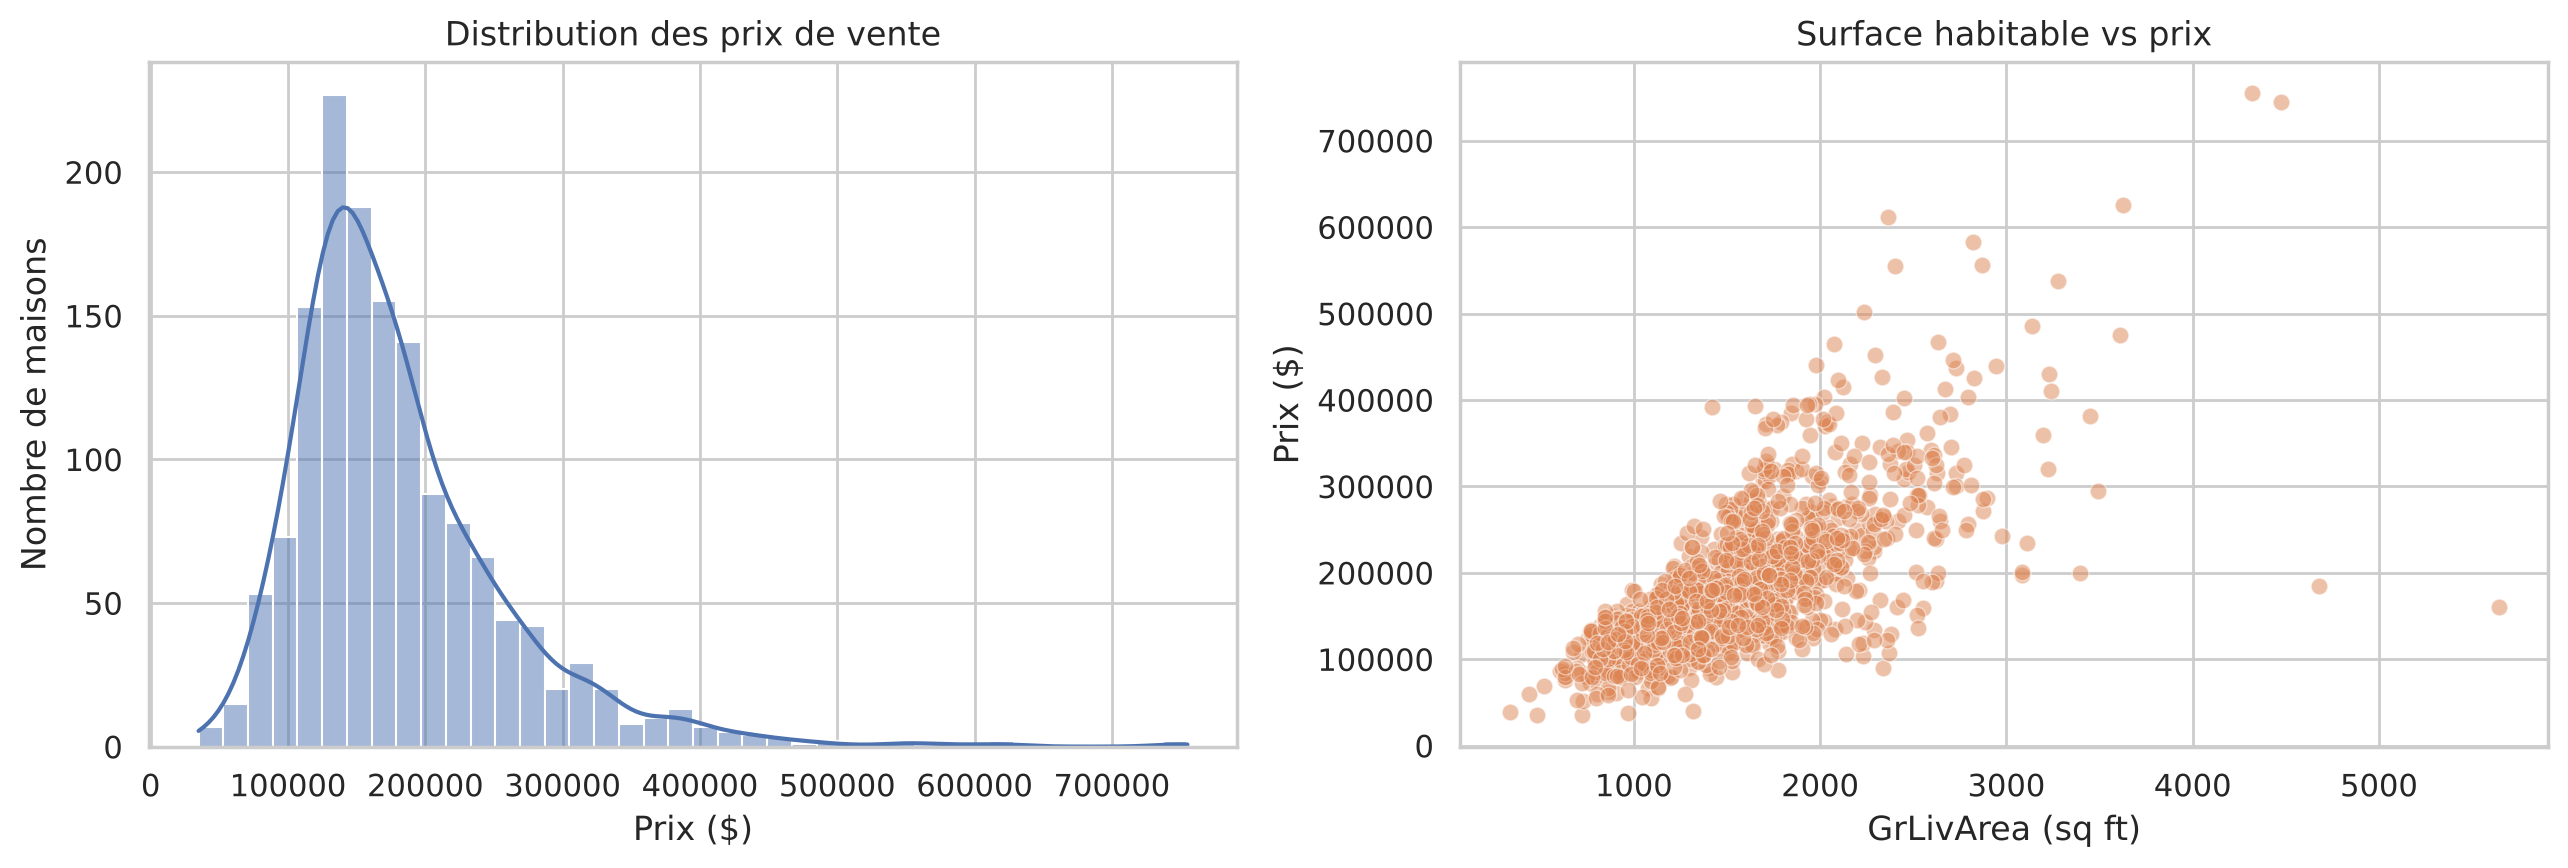

Asymétrie (skewness) du prix : 1.88


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["SalePrice"], bins=40, kde=True, ax=ax[0], color="#4c72b0")
ax[0].set(title="Distribution des prix de vente", xlabel="Prix ($)", ylabel="Nombre de maisons")
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=.5, ax=ax[1], color="#dd8452")
ax[1].set(title="Surface habitable vs prix", xlabel="GrLivArea (sq ft)", ylabel="Prix ($)")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_distribution_et_surface.png", dpi=200); plt.show()
print("Asymétrie (skewness) du prix :", round(df["SalePrice"].skew(), 2))

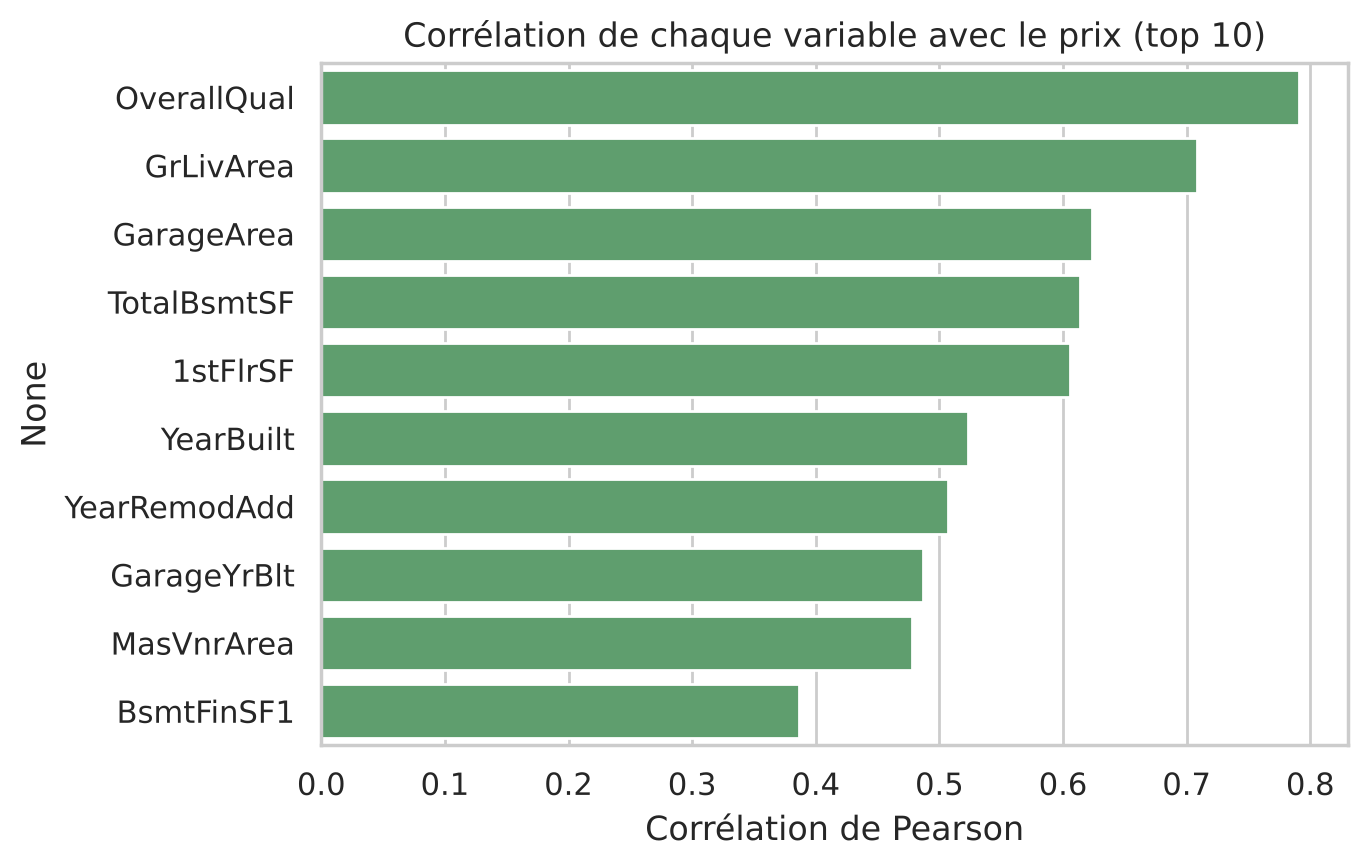

OverallQual     0.791
GrLivArea       0.709
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
YearBuilt       0.523
YearRemodAdd    0.507
GarageYrBlt     0.486
MasVnrArea      0.477
BsmtFinSF1      0.386


In [5]:
corr = df.select_dtypes("number").corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
top = corr.head(10)
plt.figure(figsize=(7, 4.5))
sns.barplot(x=top.values, y=top.index, color="#55a868")
plt.title("Corrélation de chaque variable avec le prix (top 10)"); plt.xlabel("Corrélation de Pearson")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_correlations_top10.png", dpi=200); plt.show()
print(top.round(3).to_string())

## 5. Variables retenues, encodage, Feature Engineering et séparation train / test

- Les colonnes `EnclosedPorch` et `WoodDeckSF` sont **supprimées** : plus de 89 % de valeurs manquantes.
- Il reste **21 variables explicatives**, communes aux deux fichiers. L'ordre des colonnes est **fixé explicitement** (il ne dépend plus du hasard).
- **Feature Engineering** : 6 variables dérivées sont créées à partir des caractéristiques de la maison (surface habitable totale, âge, âge depuis la rénovation, part de sous-sol aménagé, surface habitable / terrain, surface par chambre). Elles n'utilisent **jamais le prix** → aucune fuite de données. Le modèle travaille donc sur **27 variables**.
- La séparation **80 % / 20 %** est faite **avant tout prétraitement** : le jeu de test reste totalement inconnu du modèle.

In [6]:
DROP = ["EnclosedPorch", "WoodDeckSF"]
TARGET = "SalePrice"
FEATURES = [c for c in df.columns if c not in DROP + [TARGET]]   # ordre du CSV, figé
assert len(FEATURES) == 21 and set(FEATURES) <= set(df_inh.columns)

# Variables catégorielles ordinales : on conserve l'ordre de la qualité
ORDINAL = {
    "KitchenQual":  {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "BsmtFinType1": {"Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"Unf": 1, "RFn": 2, "Fin": 3},
    "BsmtExposure": {"No": 1, "Mn": 2, "Av": 3, "Gd": 4},
}

REF_YEAR = 2024   # année de référence pour calculer des âges (constante fixe)
DERIVED = ["TotalLivingArea", "PropertyAge", "RemodelAge",
           "BasementFinishRatio", "LivingToLotRatio", "AreaEfficiency"]

def encoder(frame, avec_fe=True):
    """Encodage ordinal + Feature Engineering.
    Aucune statistique n'est apprise ici (que des opérations ligne par ligne) et le prix n'est jamais utilisé :
    il n'y a donc aucun risque de fuite de données."""
    out = frame[FEATURES].copy()
    for col, mapping in ORDINAL.items():
        out[col] = out[col].map(mapping)
    if avec_fe:
        out["TotalLivingArea"]     = out["1stFlrSF"] + out["2ndFlrSF"]
        out["PropertyAge"]         = REF_YEAR - out["YearBuilt"]
        out["RemodelAge"]          = REF_YEAR - out["YearRemodAdd"]
        out["BasementFinishRatio"] = (out["BsmtFinSF1"] / out["TotalBsmtSF"].where(out["TotalBsmtSF"] > 0)).fillna(0)
        out["LivingToLotRatio"]    = out["GrLivArea"] / out["LotArea"]
        out["AreaEfficiency"]      = out["GrLivArea"] / out["BedroomAbvGr"].clip(lower=1)
    return out

X, y = encoder(df), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, shuffle=True)
print(f"Train : {len(X_train)} maisons | Test : {len(X_test)} maisons | Variables : {X_train.shape[1]} (21 d'origine + {len(DERIVED)} dérivées)")
display(X_train[DERIVED].describe().round(2).T)
print(f"Prix moyen train : ${y_train.mean():,.0f} | test : ${y_test.mean():,.0f}")

Train : 1168 maisons | Test : 292 maisons | Variables : 27 (21 d'origine + 6 dérivées)


,count,mean,std,min,25%,50%,75%,max
TotalLivingArea,1104.0,1527.41,524.78,334.00,1143.75,1474.50,1792.75,5642.00
PropertyAge,1168.0,53.03,30.68,14.00,23.00,52.00,71.00,152.00
RemodelAge,1168.0,39.10,20.73,14.00,20.00,30.00,58.00,74.00
BasementFinishRatio,1168.0,0.40,0.35,0.00,0.00,0.44,0.72,1.00
LivingToLotRatio,1168.0,0.18,0.11,0.01,0.12,0.15,0.19,0.95
AreaEfficiency,1088.0,551.04,223.78,236.80,422.38,510.50,617.00,2234.00


Prix moyen train : $181,442 | test : $178,840


## 6. Prétraitement (appris sur le train uniquement)

Le prétraitement est intégré dans un `Pipeline` scikit-learn :
1. **Imputation** : médiane pour les variables numériques, valeur la plus fréquente pour les 4 variables ordinales ;
2. **Standardisation** (`StandardScaler`).

Comme tout est dans le pipeline, la médiane et la moyenne sont calculées **sur le train seulement** (et sur le train de chaque pli en validation croisée) — aucune information du test ne fuit vers le modèle.

In [7]:
ORD_COLS = list(ORDINAL)
NUM_COLS = [c for c in X.columns if c not in ORD_COLS]   # inclut les variables dérivées

def preprocesseur():
    return ColumnTransformer(
        [("ordinales", SimpleImputer(strategy="most_frequent"), ORD_COLS),
         ("numeriques", SimpleImputer(strategy="median"), NUM_COLS)],
    ).set_output(transform="pandas")

def pipeline(modele):
    return Pipeline([("prep", preprocesseur()), ("scaler", StandardScaler()), ("modele", modele)])

## 7. Comparaison de 8 modèles de régression
Mesures : **RMSE** (erreur en dollars), **MAE** (erreur moyenne absolue), **R²** (part de variance expliquée), sur le **test** (292 maisons), et **R² en validation croisée 5 plis** sur le train. L'écart train → test révèle le sur-apprentissage.

In [8]:
MODELES = {
    "Linear Regression": LinearRegression(),
    "Ridge":             Ridge(alpha=1.0, random_state=SEED),
    "Lasso":             Lasso(alpha=0.1, random_state=SEED),
    "Decision Tree":     DecisionTreeRegressor(random_state=SEED),
    "Random Forest":     RandomForestRegressor(n_estimators=100, random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=SEED),
    "SVR":               SVR(kernel="rbf"),
    "KNN":               KNeighborsRegressor(n_neighbors=5),
}
rows, fitted = [], {}
for nom, m in MODELES.items():
    pipe = pipeline(m).fit(X_train, y_train)
    fitted[nom] = pipe
    p_tr, p_te = pipe.predict(X_train), pipe.predict(X_test)
    cv = cross_val_score(pipeline(m), X_train, y_train, cv=5, scoring="r2")
    rows.append({"Modèle": nom,
                 "RMSE test ($)": np.sqrt(mean_squared_error(y_test, p_te)),
                 "MAE test ($)": mean_absolute_error(y_test, p_te),
                 "R² test": r2_score(y_test, p_te),
                 "R² train": r2_score(y_train, p_tr),
                 "R² CV (moy.)": cv.mean(), "R² CV (écart-type)": cv.std()})
res = pd.DataFrame(rows).set_index("Modèle").sort_values("R² CV (moy.)", ascending=False)
res.round({"RMSE test ($)": 0, "MAE test ($)": 0, "R² test": 4, "R² train": 4, "R² CV (moy.)": 4, "R² CV (écart-type)": 4})

,RMSE test ($),MAE test ($),R² test,R² train,R² CV (moy.),R² CV (écart-type)
Modèle,,,,,,
Gradient Boosting,26967.0,17181.0,0.9052,0.9636,0.8458,0.0353
Random Forest,28749.0,17797.0,0.8922,0.9793,0.8389,0.0448
KNN,35373.0,21183.0,0.8369,0.8474,0.7751,0.0621
Ridge,35758.0,22159.0,0.8333,0.8081,0.7532,0.1105
Lasso,35755.0,22161.0,0.8333,0.8081,0.7525,0.1110
Linear Regression,35755.0,22161.0,0.8333,0.8081,0.7525,0.1110
Decision Tree,37589.0,26058.0,0.8158,1.0000,0.6525,0.1415
SVR,88619.0,59497.0,-0.0239,-0.0440,-0.0513,0.0333


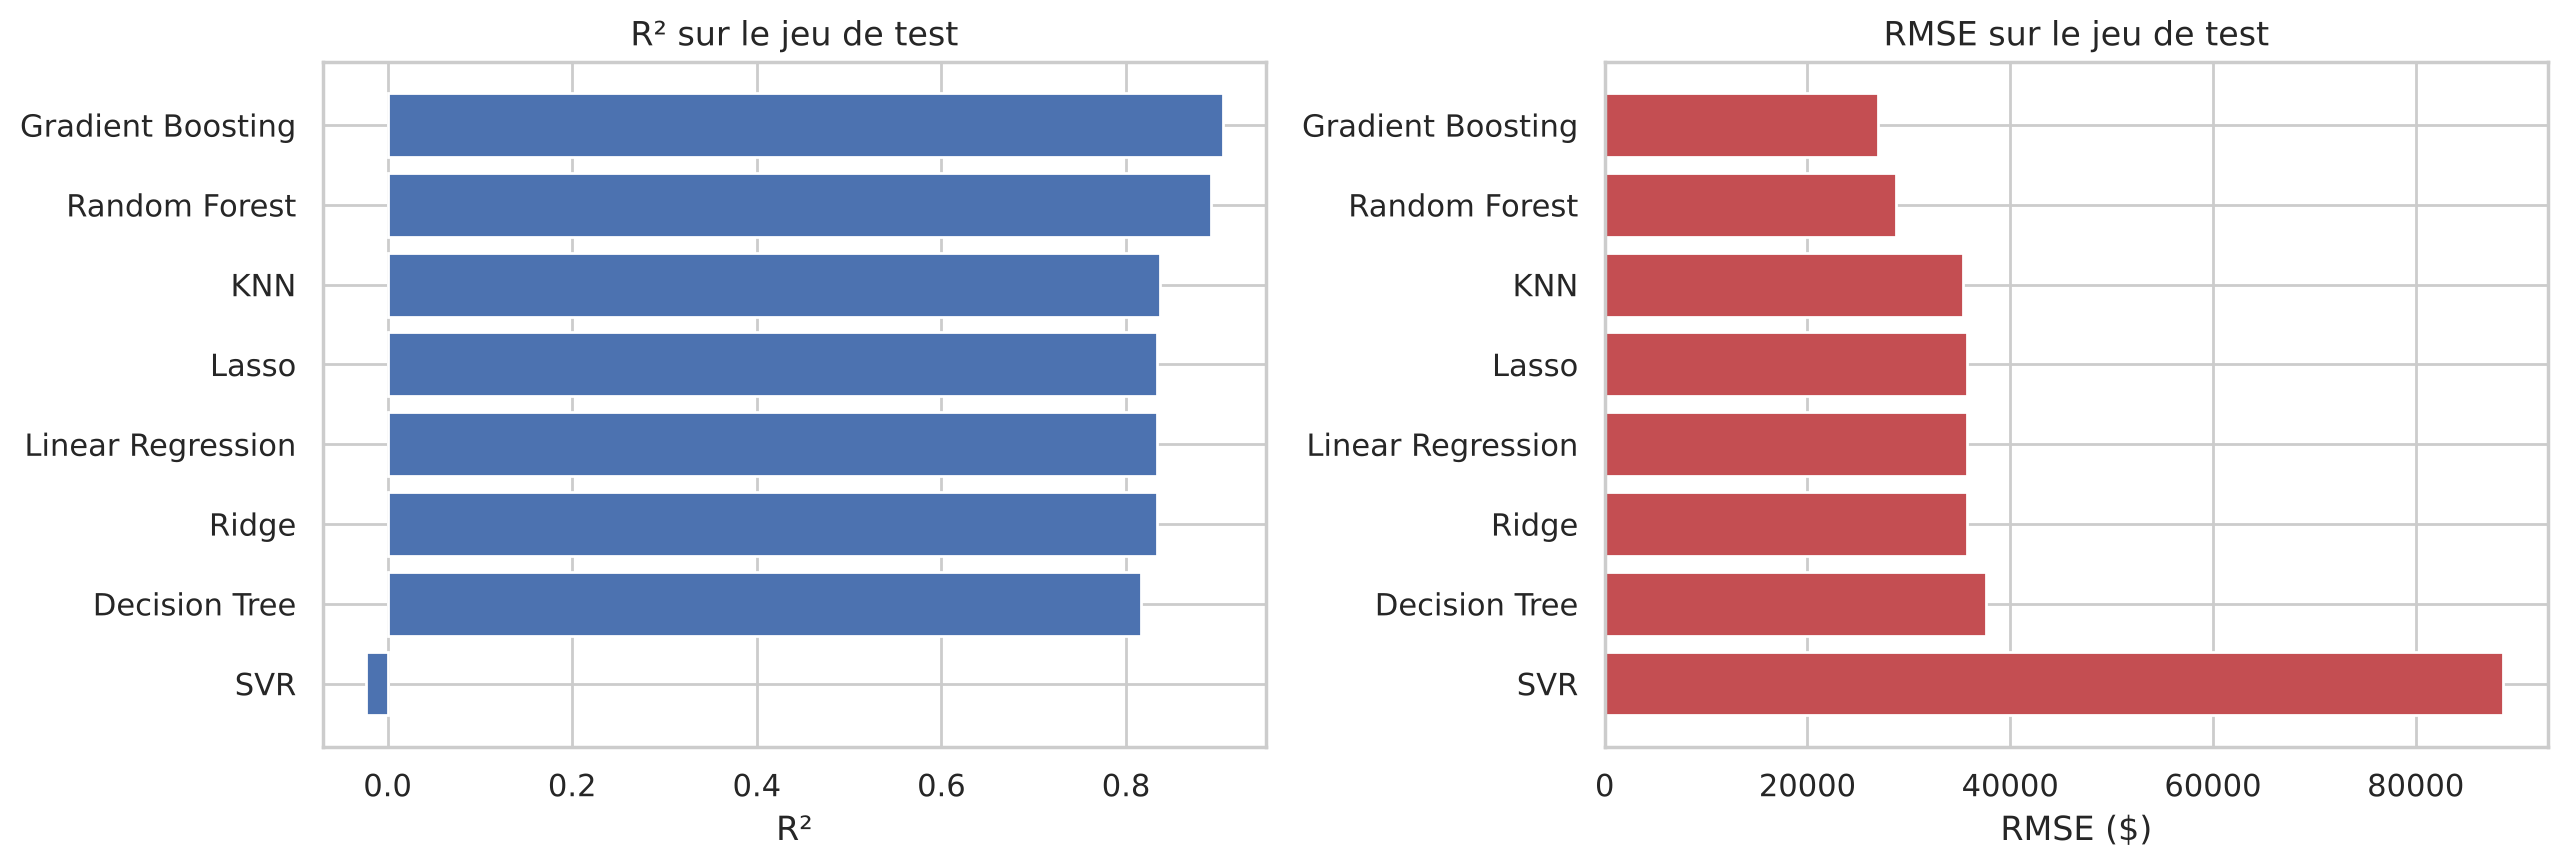

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
r = res.sort_values("R² test")
ax[0].barh(r.index, r["R² test"], color="#4c72b0"); ax[0].set(title="R² sur le jeu de test", xlabel="R²")
r = res.sort_values("RMSE test ($)", ascending=False)
ax[1].barh(r.index, r["RMSE test ($)"], color="#c44e52"); ax[1].set(title="RMSE sur le jeu de test", xlabel="RMSE ($)")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_comparaison_modeles.png", dpi=200); plt.show()

### Le Feature Engineering améliore-t-il les résultats ?
Même pipeline, mêmes séparations, avec et sans les 6 variables dérivées (R² en validation croisée sur le train, puis sur le test).

In [10]:
Xs = encoder(df, avec_fe=False)
Xs_tr, Xs_te = Xs.loc[X_train.index], Xs.loc[X_test.index]
def _pipe_sans_fe(m):
    oc = list(ORDINAL); nc = [c for c in Xs.columns if c not in oc]
    prep = ColumnTransformer([("o", SimpleImputer(strategy="most_frequent"), oc),
                              ("n", SimpleImputer(strategy="median"), nc)]).set_output(transform="pandas")
    return Pipeline([("prep", prep), ("scaler", StandardScaler()), ("modele", m)])
abl = []
for nom, m in MODELES.items():
    cv0 = cross_val_score(_pipe_sans_fe(m), Xs_tr, y_train, cv=5, scoring="r2").mean()
    te0 = r2_score(y_test, _pipe_sans_fe(clone(m)).fit(Xs_tr, y_train).predict(Xs_te))   # clone : ne touche pas aux modèles déjà entraînés
    abl.append({"Modèle": nom, "R² CV sans FE": cv0, "R² CV avec FE": res.loc[nom, "R² CV (moy.)"],
                "R² test sans FE": te0, "R² test avec FE": res.loc[nom, "R² test"]})
abl = pd.DataFrame(abl).set_index("Modèle")
abl.to_csv(MODEL_DIR / "ablation_feature_engineering.csv")
abl.round(4)

,R² CV sans FE,R² CV avec FE,R² test sans FE,R² test avec FE
Modèle,,,,
Linear Regression,0.7647,0.7525,0.8337,0.8333
Ridge,0.7648,0.7532,0.8336,0.8333
Lasso,0.7647,0.7525,0.8337,0.8333
Decision Tree,0.6752,0.6525,0.8248,0.8158
Random Forest,0.8386,0.8389,0.8931,0.8922
Gradient Boosting,0.8469,0.8458,0.8915,0.9052
SVR,-0.0513,-0.0513,-0.0238,-0.0239
KNN,0.7808,0.7751,0.8336,0.8369


## 8. Choix du modèle
Le modèle est choisi sur la **moyenne du R² en validation croisée** (calculée sur le train uniquement). Le jeu de test n'intervient pas dans le choix : il sert uniquement à mesurer la performance finale.

In [11]:
MEILLEUR = res["R² CV (moy.)"].idxmax()
top2 = res.head(2)
print("Modèle retenu :", MEILLEUR)
display(top2[["R² CV (moy.)", "R² CV (écart-type)", "R² test", "RMSE test ($)"]].round(4))
print("\nNote : l'écart entre les deux meilleurs modèles est faible ; les deux sont de bons choix.")

Modèle retenu : Gradient Boosting


,R² CV (moy.),R² CV (écart-type),R² test,RMSE test ($)
Modèle,,,,
Gradient Boosting,0.8458,0.0353,0.9052,26967.4861
Random Forest,0.8389,0.0448,0.8922,28749.0934



Note : l'écart entre les deux meilleurs modèles est faible ; les deux sont de bons choix.


## 9. Évaluation du modèle retenu sur le jeu de test (292 maisons jamais vues)

In [12]:
best = fitted[MEILLEUR]
pred = best.predict(X_test)
rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
mae  = float(mean_absolute_error(y_test, pred))
r2   = float(r2_score(y_test, pred))
err_rel = np.abs(pred - y_test) / y_test * 100
print(f"R² test   : {r2:.4f}")
print(f"RMSE test : ${rmse:,.0f}")
print(f"MAE test  : ${mae:,.0f}")
print(f"Erreur relative moyenne : {err_rel.mean():.1f} % | médiane : {err_rel.median():.1f} %")
for s in (5, 10, 15, 20):
    print(f"Prédictions à moins de {s:>2} % du prix réel : {(err_rel <= s).mean()*100:.1f} %")

R² test   : 0.9052
RMSE test : $26,967
MAE test  : $17,181
Erreur relative moyenne : 10.4 % | médiane : 6.6 %
Prédictions à moins de  5 % du prix réel : 37.3 %
Prédictions à moins de 10 % du prix réel : 67.8 %
Prédictions à moins de 15 % du prix réel : 83.2 %
Prédictions à moins de 20 % du prix réel : 90.4 %


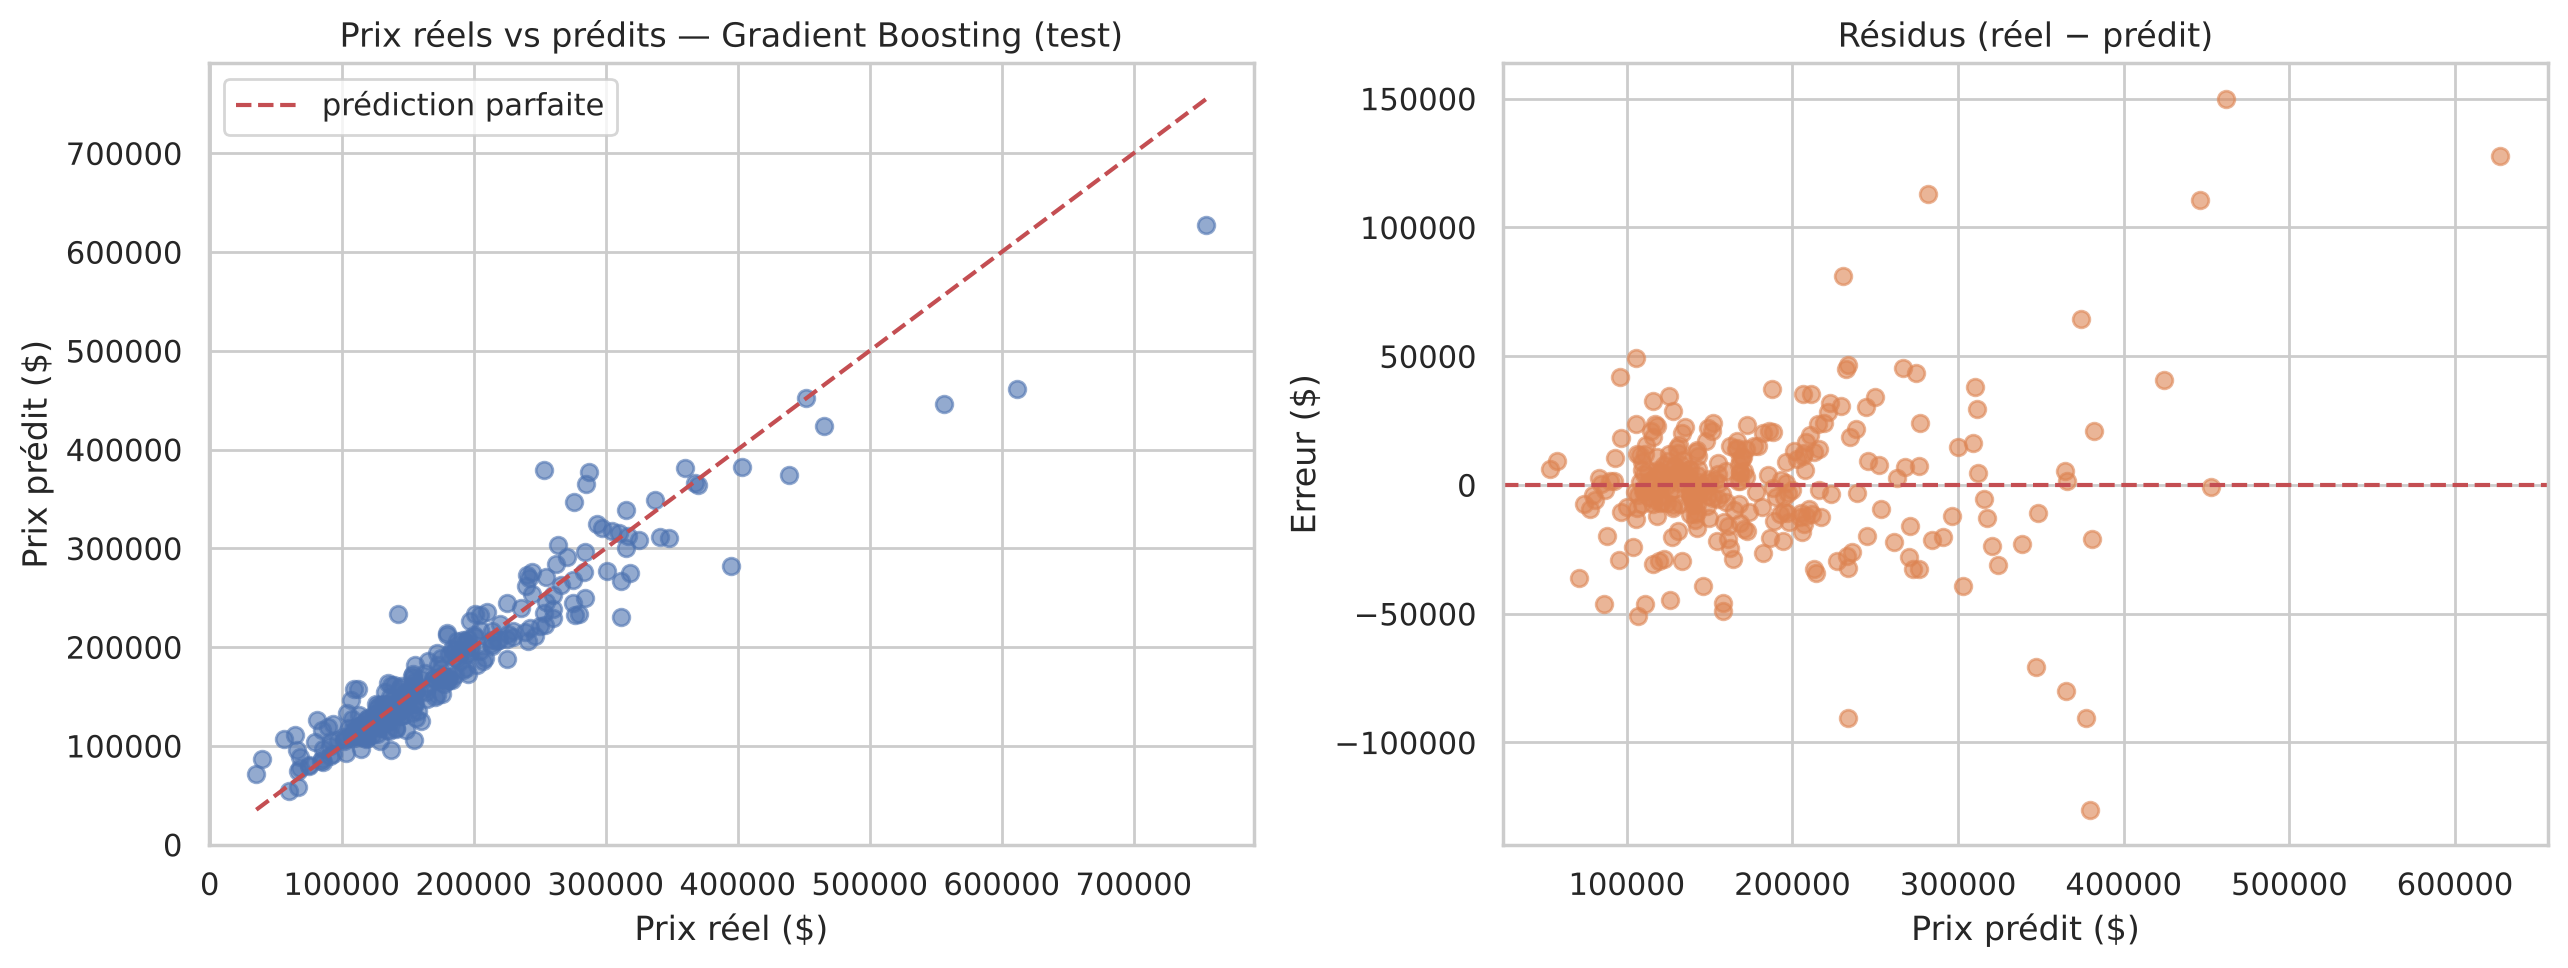

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, pred, alpha=.6, color="#4c72b0")
lim = [y_test.min(), y_test.max()]; ax[0].plot(lim, lim, "r--", label="prédiction parfaite")
ax[0].set(title=f"Prix réels vs prédits — {MEILLEUR} (test)", xlabel="Prix réel ($)", ylabel="Prix prédit ($)"); ax[0].legend()
ax[1].scatter(pred, y_test - pred, alpha=.6, color="#dd8452"); ax[1].axhline(0, color="r", ls="--")
ax[1].set(title="Résidus (réel − prédit)", xlabel="Prix prédit ($)", ylabel="Erreur ($)")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_reel_vs_predit_test.png", dpi=200); plt.show()

## 10. Importance des variables
Importance **par permutation** sur le jeu de test : baisse du R² quand on mélange une variable. Cette méthode fonctionne pour tout modèle et ne favorise pas les variables à beaucoup de valeurs.

OverallQual        0.2680
GrLivArea          0.0837
2ndFlrSF           0.0345
TotalLivingArea    0.0297
TotalBsmtSF        0.0227
BsmtFinSF1         0.0184
KitchenQual        0.0176
1stFlrSF           0.0151
LotArea            0.0151
PropertyAge        0.0112


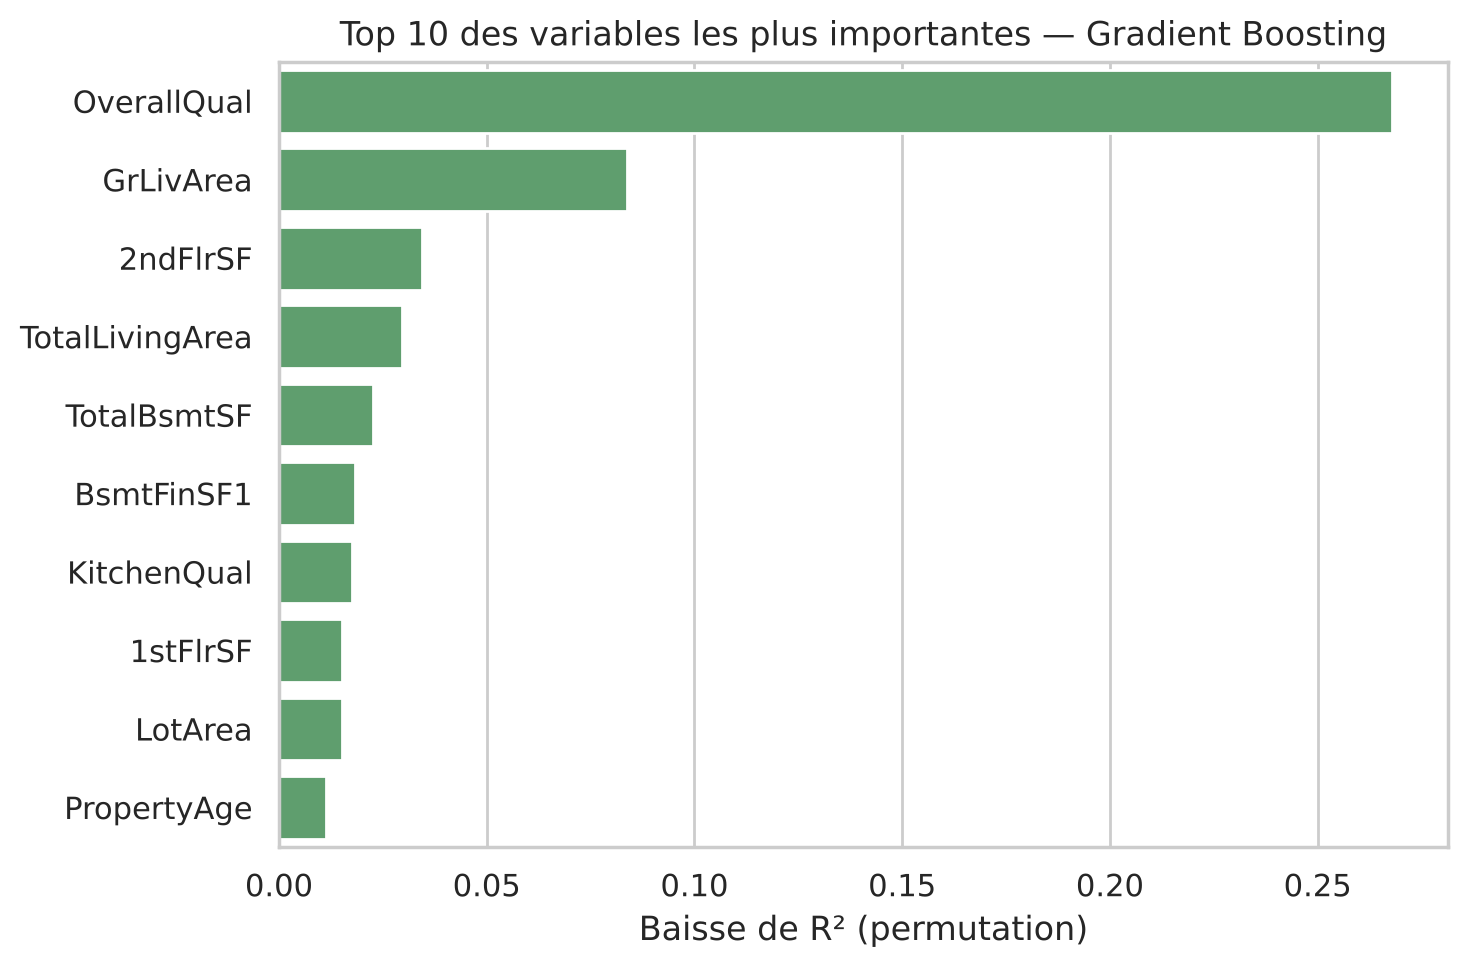

In [14]:
perm = permutation_importance(best, X_test, y_test, n_repeats=20, random_state=SEED, scoring="r2")
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp.head(10).round(4).to_string())
plt.figure(figsize=(7.5, 5))
sns.barplot(x=imp.head(10).values, y=imp.head(10).index, color="#55a868")
plt.title(f"Top 10 des variables les plus importantes — {MEILLEUR}"); plt.xlabel("Baisse de R² (permutation)"); plt.ylabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_importance_variables.png", dpi=200); plt.show()

## 11. Modèle final et estimation des 4 maisons héritées
Une fois le modèle validé, on le **réentraîne sur les 1460 maisons** pour l'application. Sa performance attendue est celle mesurée à l'étape 9 (sur des maisons non vues), **pas** son score sur les données d'entraînement.

La fourchette indiquée est « prédiction ± RMSE test » (une erreur typique), et non un pourcentage arbitraire.

In [15]:
modele_nom_classe = type(MODELES[MEILLEUR]).__name__
final = pipeline(MODELES[MEILLEUR]).fit(X, y)         # tout le jeu de données
X_inh = encoder(df_inh)
prix = final.predict(X_inh)
herit = pd.DataFrame({"Maison": [f"Maison {i+1}" for i in range(len(prix))],
                      "Prix estimé ($)": prix.round(0),
                      "Fourchette basse ($)": (prix - rmse).round(0),
                      "Fourchette haute ($)": (prix + rmse).round(0)})
display(herit.style.format({c: "{:,.0f}" for c in herit.columns[1:]}))
print(f"Total estimé des 4 maisons : ${prix.sum():,.0f}")

,Maison,Prix estimé ($),Fourchette basse ($),Fourchette haute ($)
0,Maison 1,"134,895","107,927","161,862"
1,Maison 2,"164,292","137,324","191,259"
2,Maison 3,"172,878","145,911","199,846"
3,Maison 4,"187,337","160,369","214,304"


Total estimé des 4 maisons : $659,401


## 12. Sauvegarde pour l'application

In [16]:
metadonnees = {
    "modele": MEILLEUR, "classe": modele_nom_classe,
    "features": FEATURES, "derived_features": DERIVED, "ref_year": REF_YEAR, "ordinal_mapping": ORDINAL, "seed": SEED,
    "metriques_test": {"r2": round(r2, 4), "rmse": round(rmse, 2), "mae": round(mae, 2)},
    "validation_croisee_r2": round(float(res.loc[MEILLEUR, "R² CV (moy.)"]), 4),
    "n_train": int(len(X_train)), "n_test": int(len(X_test)), "n_total": int(len(df)),
    "predictions_heritees": [round(float(p), 2) for p in prix],
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__},
}
joblib.dump(final, MODEL_DIR / "model_pipeline.joblib")
(MODEL_DIR / "model_metadata.json").write_text(json.dumps(metadonnees, indent=2, ensure_ascii=False), encoding="utf-8")

# Vérification : on recharge et on retrouve exactement les mêmes prédictions
rechargé = joblib.load(MODEL_DIR / "model_pipeline.joblib")
assert np.allclose(rechargé.predict(X_inh), prix)
print("Modèle sauvegardé et vérifié :", (MODEL_DIR / "model_pipeline.joblib").name)
res.round(4).to_csv(MODEL_DIR / "comparaison_modeles.csv")

Modèle sauvegardé et vérifié : model_pipeline.joblib


## 13. Conclusion
- Le modèle retenu est affiché à l'étape 8 ; ses performances sont mesurées sur 292 maisons **jamais vues**.
- Le prétraitement est appris sur le train uniquement ; l'ordre des variables est figé ; toutes les graines sont fixées : le notebook donne les mêmes résultats à chaque exécution.
- Le fichier `models/model_pipeline.joblib` contient tout le prétraitement et le modèle : l'application n'a qu'à appliquer l'encodage ordinal puis appeler `predict`.